In [1]:
import os
import pandas as pd
import datajoint as dj
# from datetime import datenid
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb

c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\numpy\_distributor_init.py:32: UserWarning: loaded more than 1 DLL from .libs:
c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\numpy\.libs\libopenblas.PYQHXLVVQ7VESDPUVUADXEVJOBGHJPAY.gfortran-win_amd64.dll
c:\Users\bramn\Anaconda3\envs\analysis\lib\site-packages\numpy\.libs\libopenblas.XWYDX2IKJW2NMTWSFYNGFUWKQU3LYTCZ.gfortran-win_amd64.dll
  stacklevel=1)


In [ ]:
os.chdir('../..')

%env DJ_SUPPORT_FILEPATH_MANAGEMENT=TRUE
import main
drive_path = r"V:\Data\datajoint\DJEphys"
data_path = r"T:\Data"

ft = main.load(drive_path, data_path)

env: DJ_SUPPORT_FILEPATH_MANAGEMENT=TRUE
Connecting root@10.38.76.219:3306


In [3]:
exp_table = ft.Experiment()
sess_table = ft.Session()
mouse_table = ft.Mouse()
subsess_table = ft.Subsession()
raw_table = ft.ephys_tables.EphysRaw()
raw_helper_table = ft.ephys_tables.EphysRawHelper()
events_table = ft.event_tables.SubsessionEvents()
sess_split_table = ft.SessionSplit() 
sorted_table = ft.ephys_tables.SpikeSorted()
metrics_table = ft.ephys_tables.ClusterMetrics()
subsess_spikes_table = ft.ephys_tables.SubsessionSpikes()
trials_table = ft.ephys_tables.TrialSpikes()
opto_table = ft.ephys_tables.OptoTagging()
opto_cluster_table = ft.ephys_tables.OptoCluster()
cluster_table = ft.ephys_tables.Cluster()
opto_clustering_table = ft.ephys_tables.OptoClusterClustering()
cluster_trials_table = ft.ephys_tables.ClusterTrial()
behavior_table = ft.behavior_tables.Behavioral()
behavior_trials_table = ft.behavior_tables.TrialBehavioral()
cluster_sweep_metrics_table = ft.ephys_analysis_tables.ClusterSweepMetrics()
cluster_loom_metrics_table = ft.ephys_analysis_tables.ClusterLoomMetrics()
cluster_depth_table = ft.ephys_tables.ClusterDepth()

In [ ]:
from fig_params import *

fig_path = r''

In [6]:
import get_opto_keys
from datajoint_utils import get_cluster_frs

### Data

In [ ]:
stim_types = ['EXPA', 'EXPA_60', 'EXPA_25', 'EXPW', 'EXPW_60','DIMM']
stim_types_labels = ['black expansion 100%','black expansion 60%', 'black expansion 25%', 'white expansion 100%', 'white expansion 60%', 'dimming']

conditions = ['sSC', 'dSC', 'LP']

exp_dict = {}
for cond in conditions:
    print(cond)
    frs_dict = get_cluster_frs([], stim_types, dataset_name=f'{cond}_VR_good_fr25_20260116', means=False, subsession_id='01')
    frs, depths, keys_used = frs_dict['cluster_frs'], frs_dict['cluster_depths'], frs_dict['cluster_keys']

sSC_frs, sSC_depths, sSC_keys_used = exp_dict['sSC']
dSC_frs, dSC_depths, dSC_keys_used = exp_dict['dSC']
LP_frs, LP_depths, LP_keys_used = exp_dict['LP']


sSC
Found data locally, loading...
dSC
Found data locally, loading...
LP
Found data locally, loading...


In [10]:
# Baseline subtraction of all frs
def baseline_subtract(frs, baseline_start=50, baseline_end=350):
    """Subtract baseline from firing rates."""
    baseline = np.mean(frs[:, :, :, baseline_start:baseline_end], axis=-1, keepdims=True)
    return frs - baseline

for key in sSC_frs:
    sSC_frs[key] = baseline_subtract(sSC_frs[key])
for key in dSC_frs:
    dSC_frs[key] = baseline_subtract(dSC_frs[key])
for key in LP_frs:
    LP_frs[key] = baseline_subtract(LP_frs[key])


In [ ]:
def normalize(frs, sqrt_transform=True, normalization='zscore', trial_start=2, trial_end=10):
    # expected shape: (n_cells, n_stim_types, n_trials, n_timepoints)
    print(frs.shape)
    # # sqrt transform
    if sqrt_transform:
        frs = np.sign(frs)*np.sqrt(np.abs(frs))
    if normalization == 'zscore':
        # # standardize
        frs_stand = (frs - np.mean(frs[:,:,trial_start:trial_end,:], axis=(1,2,3), keepdims=True)) / (np.std(frs[:,:,trial_start:trial_end,:], axis=(1,2,3), keepdims=True))
    elif normalization == 'baseline_zscore':
        # # standardize
        stds = np.std(frs[:,:,:,50:350], axis=(-1), keepdims=True)
        # replace stds that are 0 with 1 to avoid division by zero
        stds[stds < 1] = 1
        frs_stand = (frs - np.mean(frs[:,:,:,50:350], axis=(-1), keepdims=True)) / stds
    elif normalization == 'baseline':
        frs_stand = (frs - np.mean(frs[:,:,:,50:350], axis=(-1), keepdims=True))
    elif normalization == 'minmax':
        frs_min = np.min(frs[:,:,trial_start:trial_end,:], axis=(1,2,3), keepdims=True)
        frs_max = np.max(frs[:,:,trial_start:trial_end,:], axis=(1,2,3), keepdims=True)
        frs_stand = (frs - frs_min) / (frs_max - frs_min)
    elif normalization == 'none':
        frs_stand = frs
    # minmax normalization
    return frs_stand

def bin_stimulus_response(frs, aggr='mean', visualize=False):
    # expected shape: (n_cells, n_stim_types, n_timepoints)
    if aggr == 'mean':
        aggr_fn = np.mean
    elif aggr == 'max':
        aggr_fn = np.max
    offset = int(200*0.87)
    expa_1_1 = aggr_fn(frs[:,:,400+0*offset:400+0*offset+int(200*0.125)], axis=-1)
    expa_1_2 = aggr_fn(frs[:,:,400+0*offset+int(200*0.125):400+0*offset+int(200*0.25)], axis=-1)
    stat_1 = aggr_fn(frs[:,:,400+0*offset+int(200*0.25):400+0*offset+2*int(200*0.25)], axis=-1)
    off_1 = aggr_fn(frs[:,:,400+0*offset+2*int(200*0.25):400+1*offset], axis=-1)

    expa_2_1 = aggr_fn(frs[:,:,400+1*offset:400+1*offset+int(200*0.125)], axis=-1)
    expa_2_2 = aggr_fn(frs[:,:,400+1*offset+int(200*0.125):400+1*offset+int(200*0.25)], axis=-1)
    stat_2 = aggr_fn(frs[:,:,400+1*offset+int(200*0.25):400+1*offset+2*int(200*0.25)], axis=-1)
    off_2 = aggr_fn(frs[:,:,400+1*offset+2*int(200*0.25):400+2*offset], axis=-1)

    expa_3_1 = aggr_fn(frs[:,:,400+2*offset:400+2*offset+int(200*0.125)], axis=-1)
    expa_3_2 = aggr_fn(frs[:,:,400+2*offset+int(200*0.125):400+2*offset+int(200*0.25)], axis=-1)
    stat_3 = aggr_fn(frs[:,:,400+2*offset+int(200*0.25):400+2*offset+2*int(200*0.25)], axis=-1)
    off_1 = aggr_fn(frs[:,:,400+2*offset+2*int(200*0.25):400+3*offset], axis=-1)

    if visualize:
        fig, ax = plt.subplots(1,1, figsize=(8,3))
        ax.plot(np.mean(frs[:,:,:], axis=(0,1)))
        ax.axvline(400+0*offset, color='black', linestyle='--')
        ax.axvline(400+0*offset+int(200*0.125), color='black', linestyle='--')
        ax.axvline(400+0*offset+int(200*0.25), color='black', linestyle='--')
        ax.axvline(400+0*offset+2*int(200*0.25), color='black', linestyle='--')

        ax.axvline(400+1*offset, color='black', linestyle='--')
        ax.axvline(400+1*offset+int(200*0.125), color='black', linestyle='--')
        ax.axvline(400+1*offset+int(200*0.25), color='black', linestyle='--')
        ax.axvline(400+1*offset+2*int(200*0.25), color='black', linestyle='--')

        ax.axvline(400+2*offset, color='black', linestyle='--')
        ax.axvline(400+2*offset+int(200*0.125), color='black', linestyle='--')
        ax.axvline(400+2*offset+int(200*0.25), color='black', linestyle='--')
        ax.axvline(400+2*offset+2*int(200*0.25), color='black', linestyle='--')
        ax.axvline(400+3*offset, color='black', linestyle='--')

        plt.show()
    return np.stack([expa_1_1, expa_1_2, stat_1, off_1, expa_2_1, expa_2_2, stat_2, off_2, expa_3_1, expa_3_2, stat_3, off_1], axis=-1)

def preprocess(frs, binning):
    # Expected shape: (n_cells, n_stim_types, n_trials, n_timepoints)
    selected_stims = [0, 2, 3, 5] # ,3,5
    # trial_start, trial_end = 2, 8
    trial_start, trial_end = 2, 10

    print(frs.shape)
    # 1. Winsorizing: clip values to 99th percentile
    frs = np.clip(frs, a_min=None, a_max=np.percentile(frs, 99.9, axis=(1,2,3), keepdims=True))
    # 2. Baseline subtraction
    # Stims to use: expa, expa_25, expw, dimm
    frs_basesub = frs[:,selected_stims,:,:]
    # 3. Normalization of firing rates (z-score/min-max) 
    frs_norm = normalize(frs_basesub, sqrt_transform=True, normalization='baseline_zscore', trial_start=trial_start, trial_end=trial_end)

    # 4. Avg across trials (2:8)
    frs_avg = np.mean(frs_norm[:, :, trial_start:trial_end, :], axis=2)
    print(frs_avg.shape)
    # 4. Binning of time traces based on stimulus ...
    if binning:
        #       Baseline, first expa, first stat, first off, last off, last stat, last expa
        frs_avg = bin_stimulus_response(frs_avg, aggr='mean', visualize=False)
        print(frs_avg.shape)
    # 5. Reshape
    frs_reshaped = np.reshape(frs_avg, (frs_avg.shape[0], -1))

    print(frs_reshaped.shape)
    return frs_reshaped

In [14]:
sSC_preprocessed = {}
sSC_unpreprocessed = {}
for key in sSC_frs:
    sSC_preprocessed[key] = preprocess(sSC_frs[key], binning=True)
    sSC_unpreprocessed[key] = preprocess(sSC_frs[key], binning=False)
dSC_preprocessed = {}
dSC_unpreprocessed = {}
for key in dSC_frs:
    dSC_preprocessed[key] = preprocess(dSC_frs[key], binning=True)
    dSC_unpreprocessed[key] = preprocess(dSC_frs[key], binning=False)
LP_preprocessed = {}
LP_unpreprocessed = {}
for key in LP_frs:
    LP_preprocessed[key] = preprocess(LP_frs[key], binning=True)
    LP_unpreprocessed[key] = preprocess(LP_frs[key], binning=False)


(121, 11, 10, 2000)
(121, 4, 10, 2000)
(121, 4, 2000)
(121, 4, 12)
(121, 48)
(121, 11, 10, 2000)
(121, 4, 10, 2000)
(121, 4, 2000)
(121, 8000)
(75, 11, 10, 2000)
(75, 4, 10, 2000)
(75, 4, 2000)
(75, 4, 12)
(75, 48)
(75, 11, 10, 2000)
(75, 4, 10, 2000)
(75, 4, 2000)
(75, 8000)
(31, 11, 10, 2000)
(31, 4, 10, 2000)
(31, 4, 2000)
(31, 4, 12)
(31, 48)
(31, 11, 10, 2000)
(31, 4, 10, 2000)
(31, 4, 2000)
(31, 8000)
(49, 11, 10, 2000)
(49, 4, 10, 2000)
(49, 4, 2000)
(49, 4, 12)
(49, 48)
(49, 11, 10, 2000)
(49, 4, 10, 2000)
(49, 4, 2000)
(49, 8000)
(19, 11, 10, 2000)
(19, 4, 10, 2000)
(19, 4, 2000)
(19, 4, 12)
(19, 48)
(19, 11, 10, 2000)
(19, 4, 10, 2000)
(19, 4, 2000)
(19, 8000)
(12, 11, 10, 2000)
(12, 4, 10, 2000)
(12, 4, 2000)
(12, 4, 12)
(12, 48)
(12, 11, 10, 2000)
(12, 4, 10, 2000)
(12, 4, 2000)
(12, 8000)
(51, 11, 10, 2000)
(51, 4, 10, 2000)
(51, 4, 2000)
(51, 4, 12)
(51, 48)
(51, 11, 10, 2000)
(51, 4, 10, 2000)
(51, 4, 2000)
(51, 8000)
(26, 11, 10, 2000)
(26, 4, 10, 2000)
(26, 4, 2000)
(2

### Code

In [10]:
from decoding import get_baseline_and_test

def fix_shape(frs):
    fulllist = []
    for i in range(len(frs)):
        fulllist.append([])
        for j in range(len(frs[i])):
            fulllist[i].append([])
            for k in range(len(frs[i][j])):
                fulllist[i][j].append(frs[i][j][k])
    return np.array(fulllist)

In [11]:
def get_percentiles(vec):
    return np.percentile(vec, [25, 75])

### Detection of stimulus using logistic regression

In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold
import matplotlib.pyplot as plt
# roc curve and auc
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
from sklearn.metrics import accuracy_score, auc

def run_model(X, y, n_splits, n_repeats):
    rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats)
    # rskf.get_n_splits(X, y)
    accuracies = [] # Only use when classes are balanced!
    tprs = []
    aucs = []
    mean_fpr = np.linspace(0, 1, 100)

    for i, (train_index, test_index) in enumerate(rskf.split(X, y)):
        # print("TRAIN:", train_index, "TEST:", test_index)
        X_train, X_test = X[train_index], X[test_index]
        y_train, y_test = y[train_index], y[test_index]
        
        # fit a model
        model = LogisticRegression(solver='lbfgs', max_iter=500)
        model.fit(X_train, y_train)

        # predict probabilities
        lr_probs = model.predict_proba(X_test)

        acc = accuracy_score(y_test, np.argmax(lr_probs, axis=1))
        accuracies.append(acc)
        # print(acc)

        # keep probabilities for the positive outcome only
        lr_probs_pos = lr_probs[:, 1]

        # calculate scores
        lr_auc = roc_auc_score(y_test, lr_probs_pos)

        # calculate roc curves
        lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probs_pos)

        interp_tpr = np.interp(mean_fpr, lr_fpr, lr_tpr)
        interp_tpr[0] = 0.0
        tprs.append(interp_tpr)
        aucs.append(lr_auc)

    mean_tpr = np.mean(tprs, axis=0)
    mean_tpr[-1] = 1.0

    return mean_fpr, mean_tpr, aucs, accuracies



### For each region, for each session, for each stimulus ... detection of stimulus in region during session

In [ ]:
stim_types = ['EXPA', 'EXPA_60', 'EXPA_25', 'EXPW', 'EXPW_60','DIMM']


In [14]:
def get_response_window(stim_type):
    if 'SWEP' in stim_type:
        return [400, 800]
    else:
        return [400, 500]


In [45]:

# For each region, for each session, for each stimulus ... detection of stimulus in region during session
sSC_dict = {}
for sSC_sess_key in sSC_frs:
    sess_sSC_frs = sSC_frs[sSC_sess_key]
    sess_sSC_frs = fix_shape(sess_sSC_frs)
    for stim_idx, stim_type in enumerate(stim_types):
        response_window = get_response_window(stim_type)
        baseline_frs, stim_frs = get_baseline_and_test(sess_sSC_frs, stim_idx, response_window=response_window, response_type='mean')
        X = np.concatenate((baseline_frs, stim_frs), axis=-1).T
        y = np.concatenate((np.zeros(baseline_frs.shape[-1]), np.ones(stim_frs.shape[-1])))

        mean_fpr, mean_tpr, aucs, accuracies = run_model(X, y, n_splits=5, n_repeats=1)
        sSC_dict[sSC_sess_key,stim_type] = {'stim_type': stim_type, 'auc_mean': np.mean(aucs), 'auc_std': np.std(aucs), 'acc_mean': np.mean(accuracies), 'acc_std': np.std(accuracies), 'mean_fpr': mean_fpr, 'mean_tpr': mean_tpr}

dSC_dict = {}
for dSC_sess_key in dSC_frs:
    sess_dSC_frs = dSC_frs[dSC_sess_key]
    sess_dSC_frs = fix_shape(sess_dSC_frs)
    for stim_idx, stim_type in enumerate(stim_types):
        response_window = get_response_window(stim_type)
        baseline_frs, stim_frs = get_baseline_and_test(sess_dSC_frs, stim_idx, response_window=response_window, response_type='mean')
        X = np.concatenate((baseline_frs, stim_frs), axis=-1).T
        y = np.concatenate((np.zeros(baseline_frs.shape[-1]), np.ones(stim_frs.shape[-1])))

        mean_fpr, mean_tpr, aucs, accuracies = run_model(X, y, n_splits=5, n_repeats=1)
        dSC_dict[dSC_sess_key,stim_type] = {'stim_type': stim_type, 'auc_mean': np.mean(aucs), 'auc_std': np.std(aucs), 'acc_mean': np.mean(accuracies), 'acc_std': np.std(accuracies), 'mean_fpr': mean_fpr, 'mean_tpr': mean_tpr}

LP_dict = {}
for LP_sess_key in LP_frs:
    sess_LP_frs = LP_frs[LP_sess_key]
    sess_LP_frs = fix_shape(sess_LP_frs)
    for stim_idx, stim_type in enumerate(stim_types):
        response_window = get_response_window(stim_type)
        baseline_frs, stim_frs = get_baseline_and_test(sess_LP_frs, stim_idx, response_window=response_window, response_type='mean')
        X = np.concatenate((baseline_frs, stim_frs), axis=-1).T
        y = np.concatenate((np.zeros(baseline_frs.shape[-1]), np.ones(stim_frs.shape[-1])))

        mean_fpr, mean_tpr, aucs, accuracies = run_model(X, y, n_splits=5, n_repeats=1)
        LP_dict[LP_sess_key,stim_type] = {'stim_type': stim_type, 'auc_mean': np.mean(aucs), 'auc_std': np.std(aucs), 'acc_mean': np.mean(accuracies), 'acc_std': np.std(accuracies), 'mean_fpr': mean_fpr, 'mean_tpr': mean_tpr}



In [46]:
sSC_df = pd.DataFrame.from_dict(sSC_dict)#.melt()
dSC_df = pd.DataFrame.from_dict(dSC_dict)#.melt()
LP_df = pd.DataFrame.from_dict(LP_dict)#.melt()
sSC_df

(01942, 74R, 20230307)  \
                                                        EXPA   
stim_type                                               EXPA   
auc_mean                                                   1   
auc_std                                                    0   
acc_mean                                                 0.9   
acc_std                                             0.122474   
mean_fpr   [0.0, 0.010101010101010102, 0.0202020202020202...   
mean_tpr   [0.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, ...   

                                                              \
                                                     EXPA_60   
stim_type                                            EXPA_60   
auc_mean                                                   1   
auc_std                                                    0   
acc_mean                                                   1   
acc_std                                                    0   
mean_fpr   [0.0, 0.010101010101010102, 0.0202020202020202...   
mean_tpr   [0.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, ...   

                                                              \
                                                     EXPA_25   
stim_type                                            EXPA_25   
auc_mean                                                   1   
auc_std                                                    0   
acc_mean                                                0.95   
acc_std                                                  0.1   
mean_fpr   [0.0, 0.010101010101010102, 0.0202020202020202...   
mean_tpr   [0.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, ...   

                                                              \
                                                        EXPW   
stim_type                                               EXPW   
auc_mean                                                   1   
auc_std                                                    0   
acc_mean                                                   1   
acc_std                                                    0   
mean_fpr   [0.0, 0.010101010101010102, 0.0202020202020202...   
mean_tpr   [0.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, ...   

                                                              \
                                                     EXPW_60   
stim_type                                            EXPW_60   
auc_mean                                                   1   
auc_std                                                    0   
acc_mean                                                   1   
acc_std                                                    0   
mean_fpr   [0.0, 0.010101010101010102, 0.0202020202020202...   
mean_tpr   [0.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, ...   

                                                              \
                                                        DIMM   
stim_type                                               DIMM   
auc_mean                                                   1   
auc_std                                                    0   
acc_mean                                                   1   
acc_std                                                    0   
mean_fpr   [0.0, 0.010101010101010102, 0.0202020202020202...   
mean_tpr   [0.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, ...   

                                                              \
                                                      SWEP_4   
stim_type                                             SWEP_4   
auc_mean                                                   1   
auc_std                                                    0   
acc_mean                                                   1   
acc_std                                                    0   
mean_fpr   [0.0, 0.010101010101010102, 0.0202020202020202...   
mean_tpr   [0.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, ...   


In [49]:
sSC_auc_mean = sSC_df.T[['stim_type', 'auc_mean', 'auc_std']]#.melt()
sSC_auc_mean['reg'] = 'sSC'
dSC_auc_mean = dSC_df.T[['stim_type', 'auc_mean', 'auc_std']]#.melt()
dSC_auc_mean['reg'] = 'dSC'
LP_auc_mean = LP_df.T[['stim_type', 'auc_mean', 'auc_std']]#.melt()
LP_auc_mean['reg'] = 'LP'

auc_mean_df = pd.concat([sSC_auc_mean, dSC_auc_mean, LP_auc_mean])

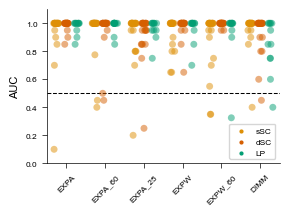

In [ ]:
# Plot auc_mean as a grouped jitter plot
auc_mean_df_sub = auc_mean_df[auc_mean_df['stim_type'].isin(['EXPA', 'EXPA_60', 'EXPA_25', 'EXPW', 'EXPW_60', 'DIMM'])] # ['SWEP_4', 'SWEP_12', 'SWEP_20', 'SWEP_50']


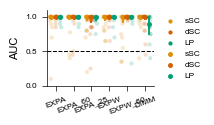

In [ ]:
# Plot auc as grouped violinplot
fig, ax = plt.subplots(1, 1, figsize=(3.5*cm, 2.5*cm))
sb.stripplot(x='stim_type', y='auc_mean', data=auc_mean_df_sub.astype({'auc_mean': 'float32'}), hue='reg', ax=ax, jitter=0.2, dodge=True, alpha=0.2, size=3, palette=[color_sSC, color_dSC, color_LP])
sb.pointplot(x='stim_type', y='auc_mean', hue='reg', data=auc_mean_df_sub.astype({'auc_mean': 'float32'}), estimator=np.median, errorbar=get_percentiles, ax=ax, palette=[color_sSC, color_dSC, color_LP], dodge=0.5, markers=["o", "o", 'o'], linestyles=["", "", ""], scale=0.8)

ax.set_ylabel('AUC')
ax.set(ylim=[0, 1.1], xlabel='')
ax.axhline(0.5, color='black', linestyle='--') # Chance level
plt.xticks(rotation=20)
# Only keep legend for the last plot
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[-3:], labels[-3:])
# Set legend on the right of plot and remove the frame
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)

plt.show()